In [2]:
# Mackenzie Brown
# Homework 7
# 10/10/2026

In [3]:
# imports 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
#import astropy.io as io
import os
from scipy.optimize import curve_fit
# hardcoded 

filename = "hw7_synthetic_transit_lightcurve.csv"


In [ ]:
print("Problem 2")
print("Article Summaries found in log entry")

In [4]:
print("Problem 3")

Problem 3


-0.05 0.05 
 0.9891198194026303 1.0015804483897377


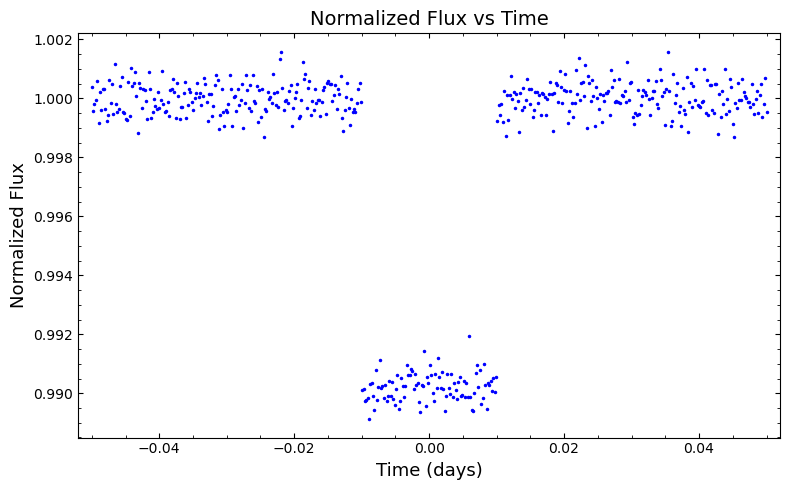

In [11]:
#3a
dat = np.loadtxt(filename, delimiter = ",", skiprows=1) # load in file
time = dat[:, 0] #assign time column
flux = dat[:, 1] # assign fluc column

fig, ax = plt.subplots(figsize = (8,5))
ax.plot(time, flux, 'b.', markersize = 3) 
ax.set_xlabel("Time (days)", fontsize = 13)
ax.set_ylabel("Normalized Flux", fontsize = 13)
ax.set_title("Normalized Flux vs Time", fontsize = 14)
ax.set_xlim(-0.052, 0.052) # extend x limits 
ax.tick_params(axis = "both", which = "both", direction = "in", top = True, right = True)
ax.minorticks_on() # add ticks on plot
fig.tight_layout()


In [6]:
#3b -----

#i 
# make box (rectangular) window function, input(array for x values obs time, location of 
#center of windwo, width, & height of function)
def box_wind(x_val, cent, wide, high):
    """
    make rectuangular box window to fit data
    Parameters:
    -----------
    x_val : array, for x values, observation time
    cent : float, center of the window
    wide : float, width of function
    high : float, height of function

    Returns:
    --------
    y_val : array, box fit onto function 

    Example:
    ---------
    >>>test_time = np.array([-0.02, -0.005, 0.0, 0.05, 0.02])
    >>>print(box_wind(test_time, 0.0, 0.01, 0.99))
    [1.   0.99 0.99 1.   1.  ]
    """
    y_val = np.ones_like(x_val) # create an array for flux outside transit (NORMALIZED)
    inside = np.abs(x_val - cent) <= wide / 2 # how far data is from center, in width bounds
    y_val[inside] = high # replace ones values with data inside half width

    return y_val


In [53]:
# ii 
# use curve fit to fit transit data with the window function

p_guess = [0.0, 0.02, 0.99] #plots center value, width of dip, and flux height of dip

popt, pcov = curve_fit(box_wind, time, flux, p0 = p_guess) # function, inital value array columns, guess

center_fit, width_fit, height_fit = popt 

model_flux = box_wind(time, center_fit, width_fit, height_fit)


/var/folders/0b/8r746f051bv5nzsl3vqj95qm0000gn/T/ipykernel_8769/1661676820.py:6: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, pcov = curve_fit(box_wind, time, flux, p0 = p_guess) # function, inital value array columns, guess


In [39]:
#iii
#print best fit parameters
print("Best Fit Center:", center_fit)
print("Best Fit Width:", width_fit, "days")
print("Best Fit Height:", height_fit)

#exoplanet radius?
stellar_rad = 1.14

fract_dec = (1 - height_fit) / 1
print(fract_dec)
r_planet = stellar_rad * np.sqrt(fract_dec)
print(r_planet)

Best Fit Center: 0.0
Best Fit Width: 0.02 days
Best Fit Height: 0.9902134794774625
0.009786520522537479
0.11277660249843363


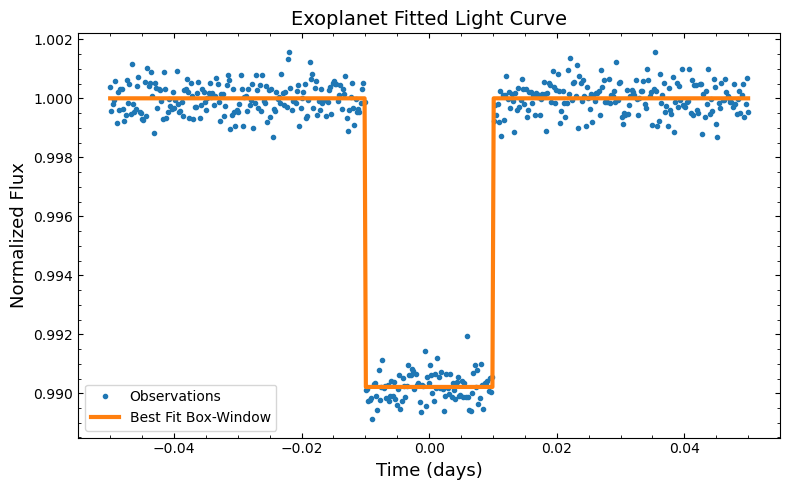

In [49]:
#iv 
fig, ax = plt.subplots(figsize = (8,5))
ax.plot(time, flux, ".",                 label = "Observations")
ax.plot(time, model_flux, linewidth = 3, label = "Best Fit Box-Window")
ax.set_title("Exoplanet Fitted Light Curve",     fontsize = 14)
ax.set_xlabel("Time (days)",     fontsize = 13)
ax.set_ylabel("Normalized Flux", fontsize = 13)
ax.tick_params(axis = "both", which = "both", direction = "in", top = True, right = True)
ax.legend()
ax.minorticks_on()
fig.tight_layout()

In [52]:
# 3c
# stellar radius error = 0.01, fractional depth error = 0.002 
#planetary radius error 

ste_err = 0.01
fra_err = 0.002 

uncert = np.sqrt((fract_dec * ste_err**2) + stellar_rad**2 / (4 * fract_dec)
                 * fra_err**2)
print("Planetary Radius Error:", uncert)


Planetary Radius Error: 0.011566051642958444
